Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier.

Data make_circles: tidak ada garis lurus yang memisahkan. Ditunjukkan bahwa
kernel linear gagal, proyeksi radial r = exp(-(X**2).sum(1)) membuat data
terpisah di ruang 3D, dan kernel RBF berhasil memisahkan di ruang 2D.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("svm_nonlinier.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\praktikum-2


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

In [3]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    P = model.decision_function(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)
    ax.contour(X, Y, P, colors="k", levels=[-1, 0, 1], alpha=0.5,
               linestyles=["--", "-", "--"])
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors="none", edgecolors="k")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


X, y = make_circles(100, factor=0.1, noise=0.1, random_state=0)
print(f"[data] make_circles X={X.shape} kelas={np.bincount(y)}")

[data] make_circles X=(100, 2) kelas=[50 50]


[linear] akurasi latih = 0.6800 (gagal, batas berupa garis lurus)


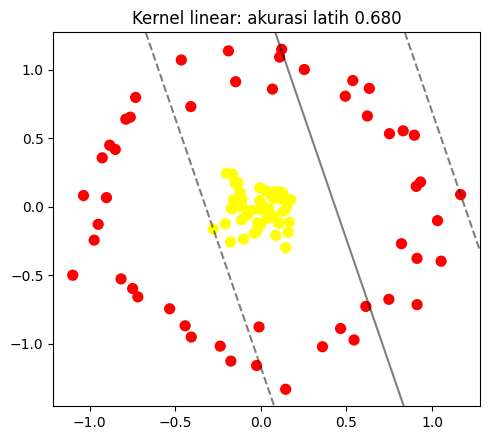

In [4]:
# --- kernel linear gagal memisahkan ---------------------------------------
clf_lin = SVC(kernel="linear").fit(X, y)
acc_lin = accuracy_score(y, clf_lin.predict(X))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
plot_svc_decision_function(clf_lin, ax, plot_support=False)
ax.set_title(f"Kernel linear: akurasi latih {acc_lin:.3f}")
fig.tight_layout()
fig.savefig(OUT / "01_linear_gagal.png", dpi=110)
print(f"[linear] akurasi latih = {acc_lin:.4f} (gagal, batas berupa garis lurus)")

[radial] proyeksi 3D disimpan (plot interaktif ipywidgets diganti 1 sudut statis)


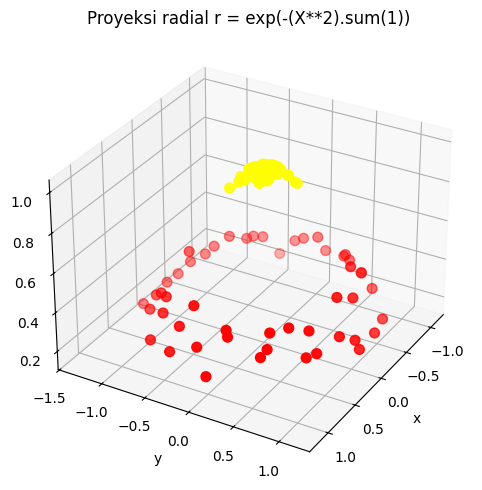

In [5]:
# --- proyeksi radial -> ruang 3D ------------------------------------------
r = np.exp(-(X ** 2).sum(1))
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap="autumn")
ax.view_init(elev=30, azim=30)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("r")
ax.set_title("Proyeksi radial r = exp(-(X**2).sum(1))")
fig.tight_layout()
fig.savefig(OUT / "02_proyeksi_radial_3d.png", dpi=110)
print("[radial] proyeksi 3D disimpan (plot interaktif ipywidgets diganti 1 sudut statis)")

[rbf] akurasi latih = 1.0000, support vector = 10


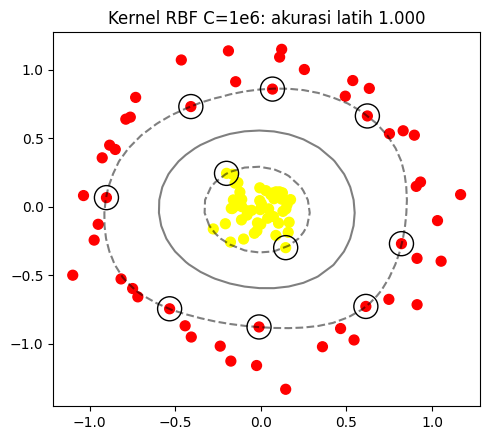

In [6]:
# --- kernel RBF berhasil ---------------------------------------------------
clf = SVC(kernel="rbf", C=1e6).fit(X, y)
acc_rbf = accuracy_score(y, clf.predict(X))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
plot_svc_decision_function(clf, ax)
ax.set_title(f"Kernel RBF C=1e6: akurasi latih {acc_rbf:.3f}")
fig.tight_layout()
fig.savefig(OUT / "03_rbf_berhasil.png", dpi=110)
print(f"[rbf] akurasi latih = {acc_rbf:.4f}, support vector = {len(clf.support_vectors_)}")

In [7]:
# perbandingan gamma kecil vs besar pada RBF
for g in [0.1, 1, 10, 100]:
    m = SVC(kernel="rbf", gamma=g, C=1e6).fit(X, y)
    print(f"[rbf] gamma={g:<5} akurasi latih = {accuracy_score(y, m.predict(X)):.4f} "
          f"SV={len(m.support_vectors_)}")
print("[selesai] praktikum 2")

[rbf] gamma=0.1   akurasi latih = 1.0000 SV=6
[rbf] gamma=1     akurasi latih = 1.0000 SV=9
[rbf] gamma=10    akurasi latih = 1.0000 SV=40
[rbf] gamma=100   akurasi latih = 1.0000 SV=74
[selesai] praktikum 2
